# 01 · Denoising regression, DDPM and DDIM

Separate what the network learns, how its output is converted, and which update generates a sample.

**Prerequisites:** Notebook 00; conditional expectation; PyTorch autograd and MSE.

**By the end:** Derive Tweedie/VP-v conversions; inspect the posterior; train a small denoiser; compare sampling methods with measured calls.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. What MSE learns

Minimizing $\mathbb E\|h(X_t,t)-Y\|^2$ gives $h^*(x,t)=\mathbb E[Y|X_t=x,t]$.
An epsilon model predicts an average compatible noise, not the hidden draw.
The conditional score is $-\epsilon/\sigma$; its average is the marginal score:
$$s_t(x)=-\mathbb E[\epsilon|x]/\sigma,\qquad
\widehat x_0=(x+\sigma^2s_t(x))/\alpha.$$
The second identity is Gaussian Tweedie. Avoid singular coefficients.
VP-v is $v=\alpha\epsilon-\sigma x_0$, giving the general conversions
$$\widehat x_0=\frac{\alpha x-\sigma\widehat v}{\alpha^2+\sigma^2},\qquad
\widehat\epsilon=\frac{\sigma x+\alpha\widehat v}{\alpha^2+\sigma^2}.$$
VP makes the denominator 1. Flow velocity is different (03).
**Code:** `training_target`, `convert_prediction` in [targets.py](../diffusion_lab/targets.py).

In [2]:
from diffusion_lab.paths import DiscreteVP, GaussianPath, expand
from diffusion_lab.targets import convert_prediction, training_target

x0, eps = torch.randn(64, 2), torch.randn(64, 2)
for kind in ["vp_linear", "ve", "sub_vp"]:
    a, s = GaussianPath(kind).coefficients(torch.full((64,), 0.3))
    xt = expand(a, x0) * x0 + expand(s, x0) * eps
    for name in ["epsilon", "x0", "score", "v"]:
        target, weight = training_target(x0, eps, a, s, name)
        recovered, recovered_eps, _ = convert_prediction(xt, target, a, s, name)
        torch.testing.assert_close(recovered, x0, atol=3e-5, rtol=3e-5)
        torch.testing.assert_close(recovered_eps, eps, atol=3e-5, rtol=3e-5)
    print(kind, "four conversions verified; alpha^2+sigma^2=", (a * a + s * s)[0].item())

vp_linear four conversions verified; alpha^2+sigma^2= 1.0
ve four conversions verified; alpha^2+sigma^2= 1.0095635652542114
sub_vp four conversions verified; alpha^2+sigma^2= 0.7607467770576477


## 2. DDPM table and forward posterior

Mathematical steps are $k=1,\ldots,T$, $a_k=1-\beta_k$ and
$\bar a_k=\prod_{j=1}^k a_j$. Signal $\alpha_k=\sqrt{\bar a_k}$,
noise $\sigma_k=\sqrt{1-\bar a_k}$. **$a_k$ is not $\alpha_k$.**
Table `i` means $k=i+1$; network time is `(i+1)/T`; clean sampling index is `-1`.
$$q(x_{k-1}|x_k,x_0)=\mathcal N(\widetilde\mu_k,\widetilde\beta_kI),$$
$$\widetilde\beta_k=\beta_k\frac{1-\bar a_{k-1}}{1-\bar a_k},\quad
\widetilde\mu_k=\frac{\sqrt{\bar a_{k-1}}\beta_k}{1-\bar a_k}x_0+
\frac{\sqrt{a_k}(1-\bar a_{k-1})}{1-\bar a_k}x_k.$$
At $k=1$ the posterior is a point mass. Code uses second-step posterior variance
for the finite first log-variance convention; the decoder is handled separately.
**Code:** [DiscreteVP](../diffusion_lab/paths.py), [posterior](../diffusion_lab/improved_ddpm.py).

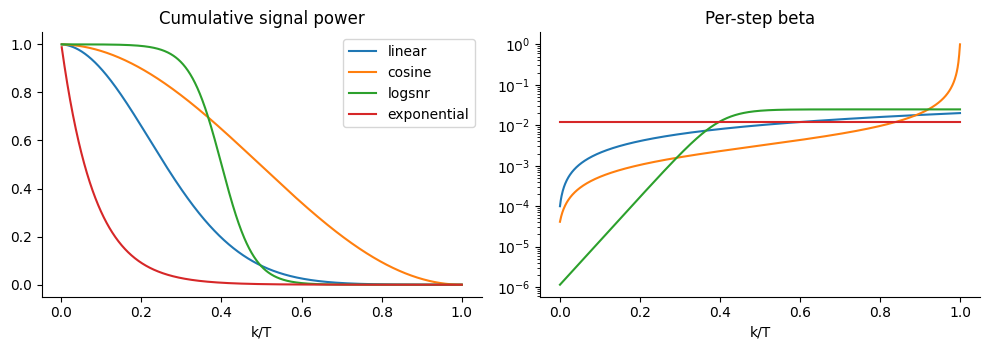

In [3]:
from diffusion_lab.improved_ddpm import posterior

path = DiscreteVP(1000, "cosine")
indices = torch.tensor([0, 10, 200, 800])
time = (indices.float() + 1) / path.steps
a, s = path.coefficients(time)
clean = torch.randn(4, 2)
noisy = expand(a, clean) * clean + expand(s, clean) * torch.randn_like(clean)
mean, logvar = posterior(path, clean, noisy, indices)
torch.testing.assert_close(mean[0], clean[0], atol=1e-5, rtol=1e-5)
fig, axes = plt.subplots(1, 2)
for schedule in ["linear", "cosine", "logsnr", "exponential"]:
    table = DiscreteVP(1000, schedule)
    axes[0].plot(torch.arange(1, 1001) / 1000, table.alpha_bar, label=schedule)
    axes[1].plot(torch.arange(1, 1001) / 1000, table.betas, label=schedule)
axes[0].set(title="Cumulative signal power", xlabel="k/T")
axes[0].legend()
axes[1].set(title="Per-step beta", xlabel="k/T", yscale="log")
plt.tight_layout()
plt.show()

## 3. Train and check on independent draws

Use the residual, time-conditioned `TimeMLP`, uniform table timesteps and clean-data MSE.
We choose x0 here because approximate epsilon predictions at the tiny terminal
alpha of a cosine table can amplify error through division by alpha. A smooth
positional time embedding is used for this short normalized-time training run.
This short CPU run is a teaching baseline. Tweedie's exact conditional clean-data average lets us measure **field error**, independent of pair-target noise.
**Code:** [models.py](../diffusion_lab/models.py); production Hydra/EMA/checkpoint loop [train.py](../diffusion_lab/train.py).

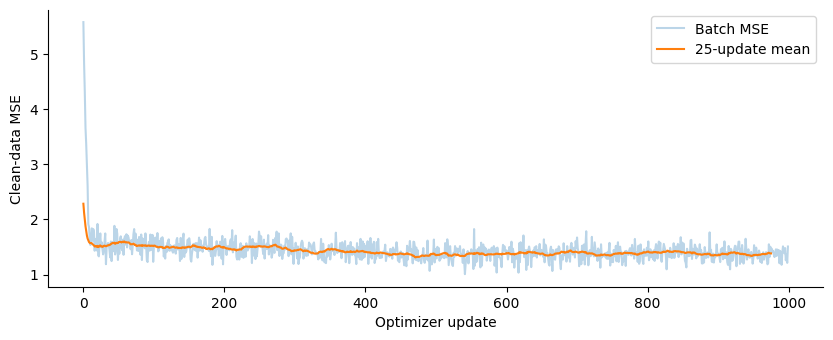

In [4]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.models import Conditioning, TimeMLP

mixture = GaussianMixture()
torch.manual_seed(21)
model = TimeMLP(width=64, depth=2)
model.condition = Conditioning(64, 0, time_embedding="positional")
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
train_rng = torch.Generator().manual_seed(21)
losses = []
for _step in range(1000):
    clean, _ = mixture.sample(256, train_rng)
    indices = torch.randint(path.steps, (len(clean),), generator=train_rng)
    time = (indices.float() + 1) / path.steps
    a, s = path.coefficients(time)
    eps = torch.randn(clean.shape, generator=train_rng)
    noisy = expand(a, clean) * clean + expand(s, clean) * eps
    loss = (model(noisy, time) - clean).square().mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
model.eval()
plt.plot(losses, alpha=0.3, label="Batch MSE")
plt.plot(np.convolve(losses, np.ones(25) / 25, mode="valid"), label="25-update mean")
plt.xlabel("Optimizer update")
plt.ylabel("Clean-data MSE")
plt.legend()
plt.show()

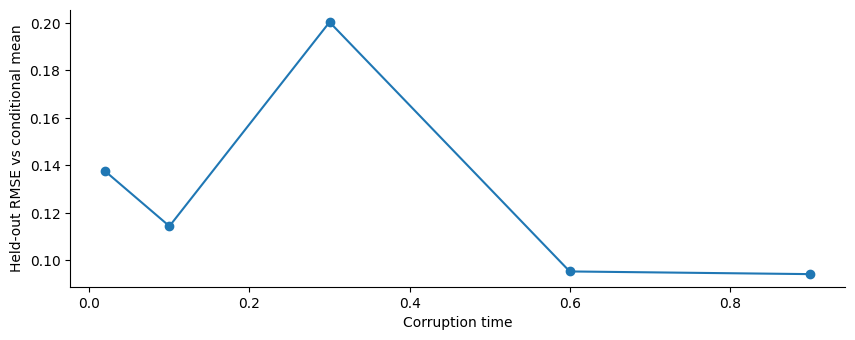

In [5]:
heldout_rng = torch.Generator().manual_seed(22)
heldout, _ = mixture.sample(512, heldout_rng)
eps = torch.randn(heldout.shape, generator=heldout_rng)
errors = []
for value in [0.02, 0.1, 0.3, 0.6, 0.9]:
    time = torch.full((len(heldout),), value)
    a, s = path.coefficients(time)
    noisy = expand(a, heldout) * heldout + expand(s, heldout) * eps
    oracle = (noisy + expand(s.square(), noisy) * mixture.score(noisy, a, s)) / expand(a, noisy)
    with torch.no_grad():
        prediction = model(noisy, time)
    errors.append((prediction - oracle).square().mean().sqrt().item())
plt.plot([0.02, 0.1, 0.3, 0.6, 0.9], errors, marker="o")
plt.xlabel("Corruption time")
plt.ylabel("Held-out RMSE vs conditional mean")
plt.show()

## 4. DDPM versus DDIM

For cumulative powers $\bar a\to\bar a'$ (toward cleaner data), DDIM uses
$$x'=\sqrt{\bar a'}\widehat x_0+\sqrt{1-\bar a'-\nu^2}\widehat\epsilon+\nu z,$$
$$\nu=\eta\sqrt{\frac{1-\bar a'}{1-\bar a}(1-\bar a/\bar a')}.$$
$\eta=0$ is deterministic given initial noise/model/grid. DDPM uses posterior
mean plus posterior noise; this code also supports ancestral respaced transitions.
The oracle predicts exact marginal conditional means, but finite-grid Gaussian
reverse transitions still incur discretization error.
**Code:** `discrete_sample` in [sampling.py](../diffusion_lab/sampling.py).

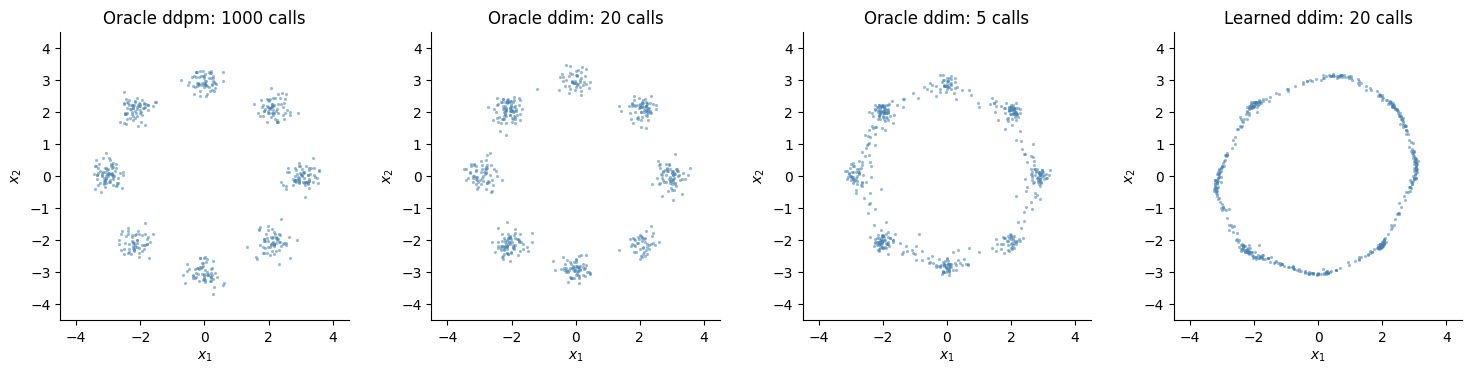

In [6]:
from diffusion_lab.sampling import discrete_sample


class OracleNoise(torch.nn.Module):
    def forward(self, x, t, labels=None):
        a, s = path.coefficients(t)
        return -expand(s, x) * mixture.score(x, a, s, labels)


class CountCalls(torch.nn.Module):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.calls = 0

    def forward(self, x, t, labels=None):
        self.calls += 1
        return self.network(x, t, labels)


initial = torch.randn(512, 2, generator=torch.Generator().manual_seed(23))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
cases = [
    (OracleNoise(), "ddpm", 1000, "epsilon"),
    (OracleNoise(), "ddim", 20, "epsilon"),
    (OracleNoise(), "ddim", 5, "epsilon"),
    (model, "ddim", 20, "x0"),
]
for ax, (network, method, steps, prediction) in zip(axes, cases, strict=True):
    counted = CountCalls(network)
    generated, _ = discrete_sample(
        counted,
        path,
        initial,
        prediction=prediction,
        method=method,
        steps=steps,
        generator=torch.Generator().manual_seed(24),
    )
    scatter(
        ax,
        generated,
        f"{'Learned' if network is model else 'Oracle'} {method}: {counted.calls} calls",
    )
plt.tight_layout()
plt.show()

In [7]:
first, _ = discrete_sample(OracleNoise(), path, initial, steps=20, eta=0)
second, _ = discrete_sample(OracleNoise(), path, initial, steps=20, eta=0)
torch.testing.assert_close(first, second, atol=0, rtol=0)
stochastic, _ = discrete_sample(
    OracleNoise(), path, initial, steps=20, eta=1, generator=torch.Generator().manual_seed(25)
)
print(
    "Same-noise eta=0 versus eta=1 RMS difference:",
    (first - stochastic).square().mean().sqrt().item(),
)

Same-noise eta=0 versus eta=1 RMS difference: 2.9126343727111816


In [8]:
class ParameterizedOracle(OracleNoise):
    def __init__(self, prediction):
        super().__init__()
        self.prediction = prediction

    def forward(self, x, t, labels=None):
        eps = super().forward(x, t, labels)
        a, s = path.coefficients(t)
        x0, _, _ = convert_prediction(x, eps, a, s, "epsilon")
        return training_target(x0, eps, a, s, self.prediction)[0]


def explore_targets(prediction="epsilon", steps=20):
    samples, _ = discrete_sample(
        ParameterizedOracle(prediction), path, initial, prediction=prediction, steps=steps
    )
    _fig, ax = plt.subplots()
    scatter(ax, samples, f"Oracle {prediction}, DDIM {steps} calls")
    plt.show()


if ENABLE_WIDGETS:
    from ipywidgets import interact

    interact(explore_targets, prediction=["epsilon", "x0", "score", "v"], steps=(2, 100, 2))

## Exercises and worked answers

1. Derive Tweedie by differentiating $p_t(x)=\int q_t(x|x_0)p_0(x_0)dx_0$.
2. Why can an exact conditional-average epsilon network have nonzero training MSE?
3. Change training budget; compare field error and mode coverage with fixed evaluation noise.

<details><summary>Worked answers</summary>

1. $\nabla\log p_t=(\alpha\mathbb E[X_0|x]-x)/\sigma^2$; rearrange.
2. Irreducible conditional variance remains, separate from approximation error.
3. Averaged loss can hide poor low-noise fields; extra sampling calls do not necessarily repair model error.

</details>

Full recipe: `python -m diffusion_lab.train experiment=gmm_cosine_x0 device=cpu`
([config](../configs/experiment/gmm_cosine_x0.yaml)).
**Continue:** [SDE/ODE/PDE](02_scores_sdes_and_odes.ipynb).
**Sources:** [DDPM](https://arxiv.org/abs/2006.11239), [DDIM](https://arxiv.org/abs/2010.02502).